# Phishing Website Risk Assessment using Machine Learning
**KDD process:** Selection → Preprocessing → Transformation → Data Mining → Evaluation / Interpretation

**Dataset:** [PhiUSIIL Phishing URL (Website), UCI](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+website)  
Target convention in source: `label = 0` phishing, `label = 1` legitimate. This notebook maps **phishing = 1** for evaluation and risk scoring.

## 1. Selection — load and inspect data

Columns: ['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

Shape: (235795, 56)

Missing values: 0

Duplicate rows: 0

Label counts

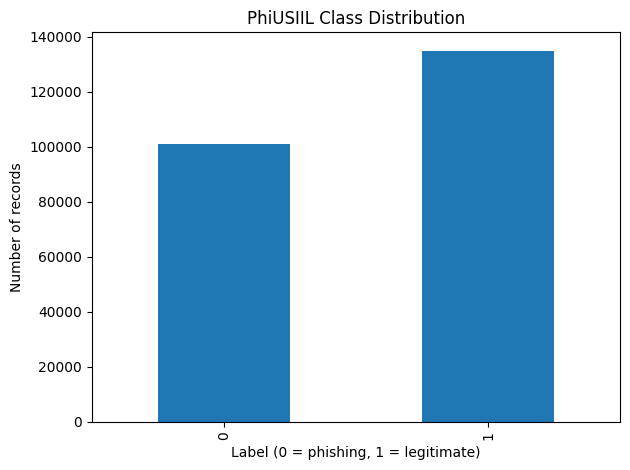

In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the downloaded dataset
dataset = pd.read_csv("./PhiUSIIL_Phishing_URL_Dataset.csv")

# Separate features and target
df = dataset.copy()

# Check that the target column exists
print("Columns:", df.columns.tolist())
assert "label" in df.columns, "Target column 'label' not found!"

df["label"] = pd.to_numeric(df["label"], errors="raise")

print("\nShape:", df.shape)
print("\nMissing values:", df.isna().sum().sum())
print("\nDuplicate rows:", df.duplicated().sum())

print("\nLabel counts (0 = phishing, 1 = legitimate):")
print(df["label"].value_counts().sort_index())

# Visualize class distribution
df["label"].value_counts().sort_index().plot(kind="bar")
plt.title("PhiUSIIL Class Distribution")
plt.xlabel("Label (0 = phishing, 1 = legitimate)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


## 2. Preprocessing and 3. Transformation — clean features and split data

In [7]:
# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Keep numeric engineered features; exclude raw text/identifier fields
X = df.drop(columns="label").select_dtypes(include=np.number).copy()

# Robust conversion handles values such as '[5E-1]' if any appear
for col in X.columns:
    X[col] = pd.to_numeric(
        X[col].astype("string").str.strip().str.replace(r"^\\[|\\]$", "", regex=True),
        errors="coerce"
    )

# Source label 0 = phishing; make phishing the positive class (1)
y = (df["label"] == 0).astype(int)

print("Rows after deduplication:", len(df))
print("Numeric features:", X.shape[1])
print("Missing numeric values:", int(X.isna().sum().sum()))
print("Phishing share:", round(y.mean() * 100, 2), "%")

Rows after deduplication: 235795
Numeric features: 50
Missing numeric values: 0
Phishing share: 42.81 %


## 4. Data Mining — train a simple baseline model

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=100, max_depth=15,
        class_weight="balanced", random_state=42, n_jobs=-1
    )
)
model.fit(X_train, y_train)
print("Training complete.")
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Training complete.
Train rows: 188636 | Test rows: 47159


## 5. Evaluation — measure performance on held-out test data

              precision    recall  f1-score   support

  Legitimate     1.0000    1.0000    1.0000     26970
    Phishing     1.0000    1.0000    1.0000     20189

    accuracy                         1.0000     47159
   macro avg     1.0000    1.0000    1.0000     47159
weighted avg     1.0000    1.0000    1.0000     47159

ROC-AUC: 1.0
PR-AUC: 1.0


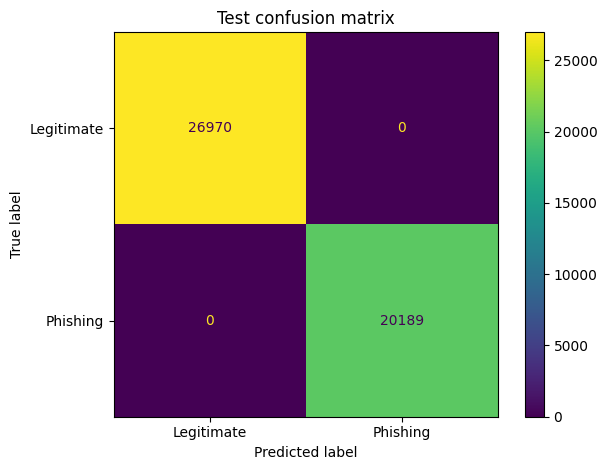

In [10]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score, ConfusionMatrixDisplay
)

pred = model.predict(X_test)
phishing_probability = model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, pred, labels=[0, 1],
    target_names=["Legitimate", "Phishing"], digits=4, zero_division=0
))
print("ROC-AUC:", round(roc_auc_score(y_test, phishing_probability), 4))
print("PR-AUC:", round(average_precision_score(y_test, phishing_probability), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, labels=[0, 1],
    display_labels=["Legitimate", "Phishing"], values_format="d"
)
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()

## 6. Interpretation — risk bands and important features

,urls,actual_phishing_rate
risk,,
Low,26970,0.0
Medium,4,1.0
High,20185,1.0


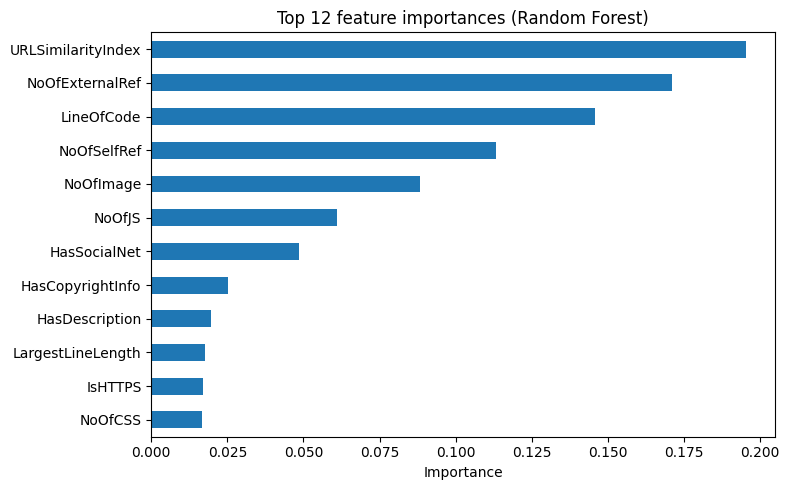

,importance
URLSimilarityIndex,0.1952
NoOfExternalRef,0.1709
LineOfCode,0.1459
NoOfSelfRef,0.1132
NoOfImage,0.0884
NoOfJS,0.0610
HasSocialNet,0.0486
HasCopyrightInfo,0.0251
HasDescription,0.0195
LargestLineLength,0.0177


In [11]:
risk = pd.cut(
    phishing_probability,
    bins=[-0.001, 0.30, 0.70, 1.001],
    labels=["Low", "Medium", "High"]
)
summary = pd.DataFrame({
    "risk": risk,
    "actual_phishing": y_test.to_numpy()
}).groupby("risk", observed=False).agg(
    urls=("actual_phishing", "size"),
    actual_phishing_rate=("actual_phishing", "mean")
).round(3)
display(summary)

rf = model.named_steps["randomforestclassifier"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)
importance.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 12 feature importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
display(importance.to_frame("importance").round(4))

## KDD Conclusion

- **Selection:** Analysed 235,795 PhiUSIIL records containing 100,945 phishing and 134,850 legitimate examples.
- **Preprocessing:** Verified zero missing values and duplicate rows in the initial dataset.
- **Transformation:** Selected numeric features, mapped phishing as the positive class, and applied a stratified 80:20 split.
- **Data Mining:** Trained a Random Forest classifier using median imputation and balanced class weights.
- **Evaluation:** Achieved 100% accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC on the test split.
- **Interpretation:** URLSimilarityIndex, NoOfExternalRef, and LineOfCode were the three most important features.

**Limitation:** Perfect scores require further investigation for data leakage and dataset-specific signals. The model uses precomputed features and does not scan live URLs.